# Notebook 19 (Revised) — SOLETE × PVOD cross-dataset synthesis

**Status:** read-only synthesis; no refitting, rescoring, hyperparameter selection, experiment revision, or file writes.

**Provenance checkpoint:** Git commit `5988fc1` (PVOD score artifacts). The three SOLETE estimates come **only from the saved, historically exposed retrospective outputs** in Notebook 16; the PVOD estimates come **only from committed Notebook 18 score tables**. No raw measurements, weight files, or local-only prediction archives are opened.

This notebook asks whether the *frozen SOLETE-selected LightGBM C1 specifications* (15 min = F1, 30/60 min = F2; 300 trees) retain descriptive improvement over **issue-time PV persistence** after **station-specific refitting** on ten PVOD stations. It does not test zero-shot weight transfer or identify the marginal effect of any individual feature family. The older F3/F4/Panchang experiments remain a separate question, not silently mixed into this primary comparison.

**Comparability rule:** SOLETE errors are reported in **kW**; PVOD errors in **per-unit** (station capacity-normalized). Never pool, average, or plot absolute cross-dataset errors. Our comparable descriptive quantity is the dimensionless **percentage reduction in MAE relative to paired issue-time persistence**, computed within each dataset and horizon.

## 1 · Establish a fail-closed, read-only provenance boundary

The notebook reads immutable, committed source bytes from `5988fc1`, checks the checkout descends from that commit, and insists locally tracked score files match their committed copies. The Git lock represents the *earlier development-only selection stage*; its historically restricted permissions are not modified by these later, separately recorded retrospective evaluations.

In [1]:
from __future__ import annotations
import hashlib
import io
import json
import os
from pathlib import Path
import re
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

SCORE_COMMIT = "5988fc1d079ea6391d98bcff66886cc6c3ef2001"
ROOT_CANDIDATES = ([Path(os.environ["SOLETE_PROJECT_ROOT"]).expanduser()]
    if os.environ.get("SOLETE_PROJECT_ROOT") else [])
ROOT_CANDIDATES += [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in ROOT_CANDIDATES
             if (p/".git").exists() and (p/"notebooks/16_revised_solete_retrospective_evaluation.ipynb").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run in the project Git checkout, or set SOLETE_PROJECT_ROOT")

def git(*args):
    return subprocess.check_output(["git", "-C", str(ROOT), *args], stderr=subprocess.STDOUT)

assert git("merge-base", "--is-ancestor", SCORE_COMMIT, "HEAD") == b""
assert git("rev-parse", SCORE_COMMIT).decode().strip() == SCORE_COMMIT

NB16 = "notebooks/16_revised_solete_retrospective_evaluation.ipynb"
LOCK = "results/development_only/revised_model_selection_lock_v1.json"
BASE = "results/external_validation/revised_pvod_lightgbm_transfer_v1_"
PATHS = {"solete": NB16, "lock": LOCK,
         "fit_manifest": BASE+"fit_manifest.json",
         "score_manifest": BASE+"score_manifest.json",
         "station_metrics": BASE+"station_metrics.csv",
         "aggregates": BASE+"aggregates.csv"}

def frozen_bytes(relative):
    raw = git("show", f"{SCORE_COMMIT}:{relative}")
    local = ROOT / relative
    assert local.is_file() and local.read_bytes() == raw, (
        f"Local source differs from committed {SCORE_COMMIT[:7]}: {relative}")
    return raw

DATA = {k: frozen_bytes(v) for k,v in PATHS.items()}
score_manifest = json.loads(DATA["score_manifest"])
fit_manifest = json.loads(DATA["fit_manifest"])
selection_lock = json.loads(DATA["lock"])
assert score_manifest["phase"] == "score_after_committed_fit"
assert score_manifest["study_classification"] == (
    "cross_dataset_retrospective_replication_previously_studied_PVOD")
assert score_manifest["no_refits_during_scoring"] is True
assert fit_manifest["phase"] == "fit_only_no_test_scoring"
assert score_manifest["fit_commit"].startswith("2235691")
assert score_manifest["fit_manifest_sha256"] == hashlib.sha256(DATA["fit_manifest"]).hexdigest()
assert score_manifest["station_metric_sha256"] == hashlib.sha256(DATA["station_metrics"]).hexdigest()
assert score_manifest["aggregate_metric_sha256"] == hashlib.sha256(DATA["aggregates"]).hexdigest()
assert score_manifest["total_station_horizon_models"] == 30
assert score_manifest["total_unique_horizon_station_test_rows"] == 161635
assert selection_lock["evaluation_policy"]["can_claim_fresh_independent_test"] is False
assert selection_lock["evaluation_policy"]["terminal_access_authorized"] is False
selection = {int(x["horizon_minutes"]): x for x in selection_lock["selected_candidates"]}
assert {h:(selection[h]["model"], selection[h]["feature_family"],
         selection[h]["configuration"]) for h in (15,30,60)} == {
    h:("LightGBM", feature, {"learning_rate":0.03,"n_estimators":300,"num_leaves":15})
    for h,feature in [(15,"F1"),(30,"F2"),(60,"F2")]}
assert fit_manifest["feature_families"] == {"15":"F1","30":"F2","60":"F2"}
assert len(fit_manifest["fits"]) == 30

print("READ-ONLY SOURCE GATE PASSED — committed checkpoint", SCORE_COMMIT[:7])
print("Frozen selection: h15 F1 | h30 F2 | h60 F2 | LightGBM C1 | 300 trees")
print("SOLETE = historically exposed retrospective | PVOD = previously studied retrospective replication")
print("NO RAW DATA / NO WEIGHTS / NO FITS / NO NEW PREDICTIONS / NO WRITES")

READ-ONLY SOURCE GATE PASSED — committed checkpoint 5988fc1
Frozen selection: h15 F1 | h30 F2 | h60 F2 | LightGBM C1 | 300 trees
SOLETE = historically exposed retrospective | PVOD = previously studied retrospective replication
NO RAW DATA / NO WEIGHTS / NO FITS / NO NEW PREDICTIONS / NO WRITES


## 2 · Recover the *recorded* SOLETE retrospective table

Notebook 16 intentionally produced **no export files**. This section parses the saved text display of its nine MAE/RMSE records and its independently displayed issue-persistence skill percentages. These are printed, **six-decimal** summaries, not reconstructed raw forecasts. A verification check tolerates only the rounding difference; no test data are reread.

In [2]:
solete_nb = json.loads(DATA["solete"])
assert len(solete_nb["cells"]) == 15

def plain_displays(cell):
    return ["".join(o.get("data", {}).get("text/plain", []))
            for o in cell.get("outputs", []) if o.get("output_type") == "display_data"]

recorded = plain_displays(solete_nb["cells"][10])
assert len(recorded) >= 1
shown = recorded[0]
# Pandas wraps this printed table into two horizontal blocks; join by row number.
pattern_mae = re.compile(
    r"^\s*(\d+)\s+(15|30|60)\s+"
    r"(LightGBM_C1_frozen|PV_at_forecast_issue|PV_at_valid_time_minus_24h)"
    r"\s+(26496)\s+(\d+\.\d+)\s*$", re.MULTILINE)
pattern_rmse = re.compile(
    r"^\s*(\d+)\s+(\d+\.\d+)\s+HISTORICALLY_EXPOSED_RETROSPECTIVE\s*$",
    re.MULTILINE)
rows = {}
for m in pattern_mae.finditer(shown):
    i,h,method,n,mae = m.groups()
    assert int(i) not in rows
    rows[int(i)] = {"horizon_min":int(h),"method":method,"n":int(n),
                    "mae_kw":float(mae)}
rmse_by_row = {int(i):float(v) for i,v in pattern_rmse.findall(shown)}
assert set(rows) == set(rmse_by_row) == set(range(9)), (
    "Notebook 16 saved pandas output format changed; inspect before proceeding")
solete = pd.DataFrame([{**rows[i],"rmse_kw":rmse_by_row[i]}
                       for i in sorted(rows)])
assert solete.groupby("horizon_min")["method"].nunique().to_dict() == {15:3,30:3,60:3}
assert solete["n"].eq(26496).all()
assert solete["rmse_kw"].ge(solete["mae_kw"]).all()

# Independently recover the displayed five-decimal skill; it is more precise
# than re-dividing the six-decimal MAE display.
shown_pct = plain_displays(solete_nb["cells"][12])
assert shown_pct
pattern_pct = re.compile(r"^\s*([012])\s+(\d+\.\d+)\s+(\d+\.\d+)\s+"
                         r"(\d+\.\d+)\s*\\?\s*$", re.MULTILINE)
pct_matches = pattern_pct.findall(shown_pct[0])
assert len(pct_matches) == 3, "Unable to locate the saved SOLETE skill values"
solete_skill = {15+15*int(i) if int(i)<2 else 60:float(pct)
                for i,_,_,pct in pct_matches}
assert set(solete_skill) == {15,30,60}
wide_solete = solete.pivot(index="horizon_min",columns="method",values="mae_kw")
assert np.allclose(
    [100*(1-wide_solete.loc[h,"LightGBM_C1_frozen"] /
               wide_solete.loc[h,"PV_at_forecast_issue"]) for h in (15,30,60)],
    [solete_skill[h] for h in (15,30,60)], atol=0.001, rtol=0)
assert all(0 < v < 100 for v in solete_skill.values())

print("NOTEBOOK 16 SAVED RETROSPECTIVE: 9/9 metric rows parsed; no SOLETE measurements read")
display(solete)
print("SOLETe recorded MAE improvement (%) vs issue persistence:", solete_skill)

NOTEBOOK 16 SAVED RETROSPECTIVE: 9/9 metric rows parsed; no SOLETE measurements read


,horizon_min,method,n,mae_kw,rmse_kw
0,15,LightGBM_C1_frozen,26496,0.259928,0.561341
1,15,PV_at_forecast_issue,26496,0.291366,0.653352
2,15,PV_at_valid_time_minus_24h,26496,0.579710,1.171413
3,30,LightGBM_C1_frozen,26496,0.301437,0.622601
4,30,PV_at_forecast_issue,26496,0.380360,0.762045
5,30,PV_at_valid_time_minus_24h,26496,0.579710,1.171413
6,60,LightGBM_C1_frozen,26496,0.341884,0.681973
7,60,PV_at_forecast_issue,26496,0.520977,0.921371
8,60,PV_at_valid_time_minus_24h,26496,0.579710,1.171413


SOLETe recorded MAE improvement (%) vs issue persistence: {15: 10.79007, 30: 20.74962, 60: 34.37627}


## 3 · Audit PVOD station metrics against the committed macro and pooled tables

For each horizon × scope × population × method group: **macro MAE/RMSE** is the arithmetic mean of ten station metrics; **pooled MAE** weights station MAEs by row count; **pooled RMSE** is the square root of row-weighted station *mean squared error* (never the weighted mean of RMSEs). We recompute all 30 aggregate records from the 300 committed station records.

In [3]:
station = pd.read_csv(io.BytesIO(DATA["station_metrics"]))
aggregate = pd.read_csv(io.BytesIO(DATA["aggregates"]))
assert len(station) == 300 and len(aggregate) == 30
assert station["station"].nunique() == 10
assert set(station["station"]) == {f"station{i:02d}" for i in range(10)}
assert station["horizon_min"].unique().tolist() == [15,30,60]
assert set(station["scope"]) == {"all", "daylight"}
assert set(station["population"]) == {"full_gap_safe", "yesterday_matched"}
assert set(station["method"]) == {"LightGBM_C1", "issue_persistence", "yesterday_persistence"}
assert not station.duplicated(["station","horizon_min","scope","population","method"]).any()
assert not aggregate.duplicated(["horizon_min","scope","population","method"]).any()
assert (station["n"] > 0).all() and np.isfinite(station[["mae_pu","rmse_pu"]]).all().all()
assert (station["rmse_pu"]+1e-10 >= station["mae_pu"]).all()
assert (station["mae_MW"].ge(0) & station["rmse_MW"].ge(0)).all()
assert np.allclose(station["mae_pu"]*station["capacity_MW"],
                   station["mae_MW"],rtol=0,atol=2e-9)
assert np.allclose(station["rmse_pu"]*station["capacity_MW"],
                   station["rmse_MW"],rtol=0,atol=2e-9)
expected_methods = {"full_gap_safe": {"LightGBM_C1","issue_persistence"},
                    "yesterday_matched": {"LightGBM_C1","issue_persistence","yesterday_persistence"}}
for (h,scope,pop), g in station.groupby(["horizon_min","scope","population"]):
    assert set(g["method"]) == expected_methods[pop]
    for method, sub in g.groupby("method"):
        assert len(sub)==10 and sub["station"].nunique()==10
    assert g.groupby("station")["n"].nunique().eq(1).all()

GROUP = ["horizon_min","scope","population","method"]
checks=[]
for keys,g in station.groupby(GROUP,sort=True):
    checks.append(dict(zip(GROUP,keys)) | {
        "station_count":g["station"].nunique(),
        "pooled_test_rows":int(g["n"].sum()),
        "macro_mae_pu":float(g["mae_pu"].mean()),
        "macro_rmse_pu":float(g["rmse_pu"].mean()),
        "pooled_mae_pu":float(np.average(g["mae_pu"],weights=g["n"])),
        "pooled_rmse_pu":float(np.sqrt(np.average(g["rmse_pu"]**2,weights=g["n"])))})
recomputed = pd.DataFrame(checks)
verify = aggregate.merge(recomputed,on=GROUP,validate="one_to_one",suffixes=("_file","_calc"))
assert len(verify) == 30
for name in ["station_count","pooled_test_rows"]:
    assert (verify[f"{name}_file"]==verify[f"{name}_calc"]).all(), name
for name in ["macro_mae_pu","macro_rmse_pu","pooled_mae_pu","pooled_rmse_pu"]:
    assert np.allclose(verify[f"{name}_file"],verify[f"{name}_calc"],
                       rtol=0,atol=1e-9),name

# The previous-day baseline is available for every record; the matched subset
# equals the full gap-safe test population on this release.
for (h,scope,method),sub in station.groupby(["horizon_min","scope","method"]):
    if method=="yesterday_persistence":
        continue
    full=sub[sub["population"]=="full_gap_safe"].set_index("station")
    matched=sub[sub["population"]=="yesterday_matched"].set_index("station")
    assert np.array_equal(full.loc[matched.index,"n"],matched["n"])
    assert np.allclose(full.loc[matched.index,"mae_pu"],matched["mae_pu"],atol=1e-12)

primary_rows = station.loc[(station["scope"]=="all") &
                           (station["population"]=="full_gap_safe")].copy()
assert len(primary_rows)==60
assert primary_rows.groupby("horizon_min")["n"].sum().to_dict() == {
    15:107770,30:107760,60:107740}  # two methods per same test row
assert int(primary_rows["n"].sum()/2) == 161635
print("PVOD AGGREGATE RECONCILIATION: 30/30 rows match station-level arithmetic")
print("STATION METRICS: 300/300 rows | no row-level prediction archive needed")

PVOD AGGREGATE RECONCILIATION: 30/30 rows match station-level arithmetic
STATION METRICS: 300/300 rows | no row-level prediction archive needed


## 4 · Primary cross-dataset comparison on a dimensionless scale

Each reported percentage is **100 × (1 − MAE_model / MAE_issue-persistence)**. SOLETE has one site and one historically exposed retrospective period. PVOD's main summary is the *equal-station* mean MAE across its ten stations. The pooled PVOD result is a different estimand and is shown as a sensitivity descriptor, not substituted for the macro result.

In [4]:
expected_families = {15:"F1",30:"F2",60:"F2"}
rows=[]
for h in (15,30,60):
    subset = aggregate.loc[(aggregate["horizon_min"]==h) &
                           (aggregate["scope"]=="all") &
                           (aggregate["population"]=="full_gap_safe")].set_index("method")
    assert set(subset.index)=={"LightGBM_C1","issue_persistence"}
    model,base = subset.loc["LightGBM_C1"], subset.loc["issue_persistence"]
    assert int(model["pooled_test_rows"]) == int(base["pooled_test_rows"])
    rows.append({"horizon_min":h,"family":expected_families[h],
        "solete_skill_pct_reported":solete_skill[h],
        "pvod_macro_skill_pct":100*(1-model["macro_mae_pu"]/base["macro_mae_pu"]),
        "pvod_pooled_skill_pct":100*(1-model["pooled_mae_pu"]/base["pooled_mae_pu"]),
        "pvod_macro_model_mae_pu":model["macro_mae_pu"],
        "pvod_macro_issue_mae_pu":base["macro_mae_pu"],
        "pvod_test_rows":int(model["pooled_test_rows"])})
comparison = pd.DataFrame(rows)
comparison["pvod_minus_solete_skill_pp"] = (
    comparison["pvod_macro_skill_pct"]-comparison["solete_skill_pct_reported"])
assert len(comparison)==3
assert np.allclose(comparison["pvod_macro_skill_pct"],
                   [11.46,26.61,41.95],rtol=0,atol=0.015)
print("Comparable *relative* MAE skill — do not compare raw kW and p.u. errors")
display(comparison.round(5))

# Daylight-only context applies to PVOD only; SOLETE Notebook 16 did not
# produce an independently defined daylight-only comparison.
daylight=[]
for h in (15,30,60):
    data=aggregate.loc[(aggregate["horizon_min"]==h) &
                       (aggregate["scope"]=="daylight") &
                       (aggregate["population"]=="full_gap_safe")].set_index("method")
    daylight.append({"horizon_min":h,"test_rows":int(data.loc["LightGBM_C1","pooled_test_rows"]),
        "macro_model_mae_pu":data.loc["LightGBM_C1","macro_mae_pu"],
        "macro_issue_mae_pu":data.loc["issue_persistence","macro_mae_pu"],
        "skill_pct":100*(1-data.loc["LightGBM_C1","macro_mae_pu"] /
                               data.loc["issue_persistence","macro_mae_pu"])})
daylight_table=pd.DataFrame(daylight)
assert daylight_table["test_rows"].eq(31222).all()
print("PVOD daylight-only (not paired with any SOLETE daylight comparison):")
display(daylight_table.round(5))

Comparable *relative* MAE skill — do not compare raw kW and p.u. errors


,horizon_min,family,solete_skill_pct_reported,pvod_macro_skill_pct,pvod_pooled_skill_pct,pvod_macro_model_mae_pu,pvod_macro_issue_mae_pu,pvod_test_rows,pvod_minus_solete_skill_pp
0,15,F1,10.79007,11.45462,13.83121,0.02350,0.02654,53885,0.66455
1,30,F2,20.74962,26.60810,28.70683,0.02919,0.03977,53880,5.85848
2,60,F2,34.37627,41.94935,44.02830,0.03742,0.06446,53870,7.57308


PVOD daylight-only (not paired with any SOLETE daylight comparison):


,horizon_min,test_rows,macro_model_mae_pu,macro_issue_mae_pu,skill_pct
0,15,31222,0.03886,0.04556,14.71801
1,30,31222,0.04833,0.06811,29.04657
2,60,31222,0.06152,0.10950,43.81888


## 5 · Station-by-station outcomes, exceptions, and sensitivity

Station-level comparisons use identical rows for each model and baseline. A **station-resampling interval** (20,000 paired resamples of the ten stations, fixed seed) summarizes sensitivity of the equal-station macro-skill estimate to which stations are sampled. With only ten geographically clustered stations and one test window each, these are **descriptive sensitivity intervals**, **not confirmatory confidence intervals or significance tests**. Temporal serial dependence is not captured. We also report nine-station leave-one-out ranges.

In [5]:
station_wide = primary_rows.pivot(index=["station","horizon_min"],columns="method",values="mae_pu")
assert station_wide.shape==(30,2)
station_wide["skill_pct"] = 100*(1-station_wide["LightGBM_C1"]/
                              station_wide["issue_persistence"])
station_wide["model_lower_mae"] = station_wide["skill_pct"] > 0
outcomes = station_wide.reset_index()
assert outcomes.groupby("horizon_min")["model_lower_mae"].sum().to_dict()=={15:8,30:10,60:10}
exceptions = outcomes.loc[~outcomes["model_lower_mae"],["station","horizon_min","skill_pct"]]
assert set(map(tuple,exceptions[["station","horizon_min"]].to_numpy()))=={
    ("station05",15),("station09",15)}
print("PER-HORIZON MODEL WINS:",outcomes.groupby("horizon_min")["model_lower_mae"].sum().to_dict())
print("NEGATIVE SKILL EXCEPTIONS:")
display(exceptions.round(4))
print("ALL STATION-LEVEL SKILLS (%):")
display(outcomes.pivot(index="station",columns="horizon_min",values="skill_pct").round(2))

rng = np.random.default_rng(42)
idx = rng.integers(0,10,size=(20_000,10))
interval_rows=[]
for h in (15,30,60):
    one=outcomes.loc[outcomes["horizon_min"]==h].sort_values("station")
    assert len(one)==10
    model=one["LightGBM_C1"].to_numpy(dtype=np.float64)
    baseline=one["issue_persistence"].to_numpy(dtype=np.float64)
    sampled_skill=100*(1-model[idx].mean(axis=1)/baseline[idx].mean(axis=1))
    loo=[100*(1-np.delete(model,k).mean()/np.delete(baseline,k).mean()) for k in range(10)]
    interval_rows.append({"horizon_min":h,"n_stations":10,"repetitions":len(idx),
        "observed_macro_skill_pct":100*(1-model.mean()/baseline.mean()),
        "station_resample_q025_pct":float(np.quantile(sampled_skill,0.025)),
        "station_resample_q975_pct":float(np.quantile(sampled_skill,0.975)),
        "leave_one_out_min_pct":min(loo),"leave_one_out_max_pct":max(loo)})
sensitivity = pd.DataFrame(interval_rows)
assert np.allclose(sensitivity["observed_macro_skill_pct"],
                   comparison["pvod_macro_skill_pct"],atol=1e-8,rtol=0)
print("PVOD equal-station macro skill: sensitivity to station selection, NOT formal inference")
display(sensitivity.round(3))

PER-HORIZON MODEL WINS: {15: 8, 30: 10, 60: 10}
NEGATIVE SKILL EXCEPTIONS:


method,station,horizon_min,skill_pct
15,station05,15,-16.4644
27,station09,15,-7.3287


ALL STATION-LEVEL SKILLS (%):


horizon_min,15,30,60
station,,,
station00,17.20,28.97,46.31
station01,22.20,37.06,53.04
station02,18.29,34.36,51.67
station03,16.45,29.61,38.56
station04,10.88,26.28,39.58
station05,-16.46,2.31,21.14
station06,16.79,31.62,45.22
station07,12.95,26.03,40.89
station08,17.24,30.61,46.70


PVOD equal-station macro skill: sensitivity to station selection, NOT formal inference


,horizon_min,n_stations,repetitions,observed_macro_skill_pct,station_resample_q025_pct,station_resample_q975_pct,leave_one_out_min_pct,leave_one_out_max_pct
0,15,10,20000,11.455,3.548,17.288,10.163,14.772
1,30,10,20000,26.608,19.792,31.753,25.319,29.598
2,60,10,20000,41.949,35.862,47.251,40.510,44.522


## 6 · Display the cross-dataset summary (no exported images)

The figure compares **relative** skills only. Its station-resampling intervals describe the PVOD station set and **must not** be interpreted as proving transfer significance. A second figure makes the two 15-minute station exceptions visible rather than hiding them inside the macro average.

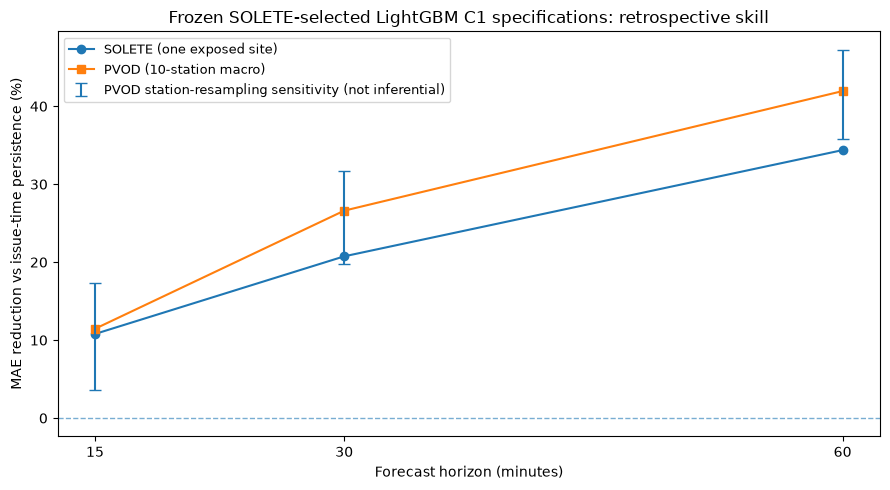

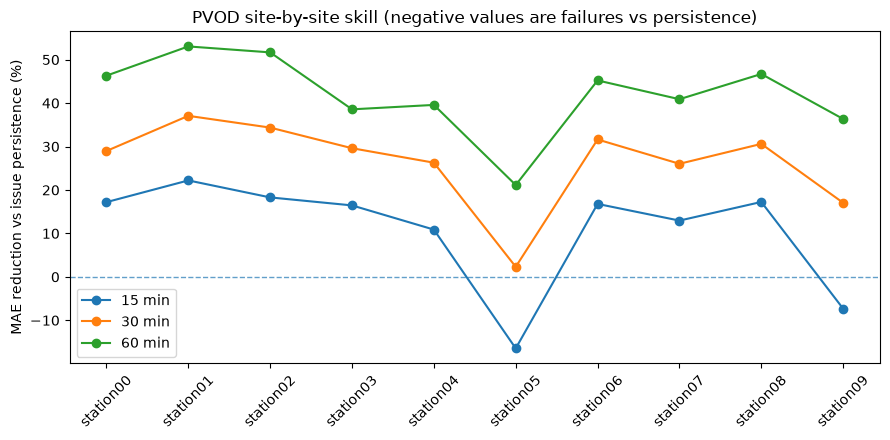

In [6]:
import matplotlib.pyplot as plt

fig,ax=plt.subplots(figsize=(9,5))
x=np.array([15,30,60],dtype=float)
ax.plot(x,comparison["solete_skill_pct_reported"],marker="o",label="SOLETE (one exposed site)")
ax.plot(x,comparison["pvod_macro_skill_pct"],marker="s",label="PVOD (10-station macro)")
low=sensitivity["observed_macro_skill_pct"]-sensitivity["station_resample_q025_pct"]
high=sensitivity["station_resample_q975_pct"]-sensitivity["observed_macro_skill_pct"]
ax.errorbar(x,comparison["pvod_macro_skill_pct"],
            yerr=[low.to_numpy(),high.to_numpy()],fmt="none",capsize=4,
            label="PVOD station-resampling sensitivity (not inferential)")
ax.axhline(0,linewidth=1,linestyle="--",alpha=0.6)
ax.set_xticks([15,30,60]);ax.set_xlabel("Forecast horizon (minutes)")
ax.set_ylabel("MAE reduction vs issue-time persistence (%)")
ax.set_title("Frozen SOLETE-selected LightGBM C1 specifications: retrospective skill")
ax.legend(loc="best",fontsize=9);fig.tight_layout();plt.show()

fig2,ax2=plt.subplots(figsize=(9,4.5))
for h,part in outcomes.groupby("horizon_min"):
    ax2.plot(part.sort_values("station")["station"],
             part.sort_values("station")["skill_pct"],marker="o",label=f"{h} min")
ax2.axhline(0,linewidth=1,linestyle="--",alpha=0.7)
ax2.set_ylabel("MAE reduction vs issue persistence (%)")
ax2.set_title("PVOD site-by-site skill (negative values are failures vs persistence)")
ax2.tick_params(axis="x",rotation=45);ax2.legend();fig2.tight_layout();plt.show()

## 7 · Audit conclusions and boundaries

**Permitted descriptive conclusions**

- The fixed SOLETE-selected LightGBM C1 *specifications* outperform issue-time persistence on their historically exposed SOLETE retrospective evaluation at all three horizons.
- With **new station-specific fits**, those same frozen specifications outperform issue-time persistence on the PVOD **equal-station macro** comparison at all horizons, and at 28/30 individual station–horizon combinations. Two sites lose at 15 minutes.
- The relative skill is higher at longer horizons *within these evaluations*, but horizons also use different feature families (15 = F1; 30/60 = F2); the design does **not** isolate horizon effects from family effects.
- The PVOD daylight-only macro comparison is positive for all three horizons, but no corresponding SOLETE daylight-only retrospective metric was exported.

**Claims not established**

- No blind independent generalization: both SOLETE terminal data and this PVOD release were previously examined during the broader research.
- No zero-shot geographic transfer of fitted weights: PVOD models were **refitted per station**, with SOLETE-selected specifications held fixed.
- No proof that F2 improves on F1, nor that Panchang F4 has a useful or causal effect: these are different experimental questions, requiring matched comparisons.
- No formal uncertainty claim from station-bootstrap sensitivity alone; ten geographically related stations, serial dependence, and legacy exposure limit interpretation.
- No tuning, model selection, new training, test rescoring, raw-data access or output exports are performed in Notebook 19.

**Next step:** review the executed output, then preserve Notebook 19 in Git and plan manuscript updates against the checked numbers. Clean older notebooks **only after** the synthesis has been reviewed and archived.

In [7]:
assert len(solete)==9 and len(station)==300 and len(aggregate)==30
assert len(comparison)==3 and len(outcomes)==30 and len(sensitivity)==3
assert list(comparison["horizon_min"])==[15,30,60]
assert int(outcomes["model_lower_mae"].sum())==28
assert (comparison["pvod_macro_skill_pct"]>0).all()
assert (comparison["solete_skill_pct_reported"]>0).all()
print("NOTEBOOK 19: READ-ONLY CROSS-DATASET SYNTHESIS VERIFIED")
print("Source checkpoint:",SCORE_COMMIT)
print("SOLETE: 9 saved retrospective metric rows (display precision only)")
print("PVOD: 300 verified station rows; 30/30 aggregates reconciled")
print("Primary: 28/30 PVOD station–horizon MAE wins; no model fitted or scored here")
print("NO INDEPENDENT-TEST CLAIM | NO CAUSAL PANCHANG CLAIM | NO FILE WRITES")

NOTEBOOK 19: READ-ONLY CROSS-DATASET SYNTHESIS VERIFIED
Source checkpoint: 5988fc1d079ea6391d98bcff66886cc6c3ef2001
SOLETE: 9 saved retrospective metric rows (display precision only)
PVOD: 300 verified station rows; 30/30 aggregates reconciled
Primary: 28/30 PVOD station–horizon MAE wins; no model fitted or scored here
NO INDEPENDENT-TEST CLAIM | NO CAUSAL PANCHANG CLAIM | NO FILE WRITES
